# 03 · Tightly focused lemon field and polarization Möbius strip

This notebook first shows the **complete three-component focal-plane field** of the lemon input: total and Cartesian-component intensities, three-dimensional polarization ellipses, principal axes and directed normals. It then follows those same polarization axes around a closed contour to study the Möbius ribbon.

Only the **lemon input** is calculated. Run all cells in order in a standard CPU Colab runtime. The HTML explorer is the same renderer used by notebook 02; it provides two rotatable views, browser-side display controls, and offline export. Notebook 02 remains unchanged.

| Section | Result |
| --- | --- |
| 1–2 | Optical parameters, lemon pupil and vectorial solver |
| 3 | Total/component intensity maps and numerical field export |
| 4 | Static 3D ellipses, principal axes and directed normals |
| 5 | Interactive HTML polarization explorer |
| 6–7 | C-point location and explicit Möbius ribbon |
| 8–9 | Topology checks, convergence and downloadable bundle |

## 1. Setup and incident lemon field

We use $\operatorname{Re}(\mathbf E e^{-i\omega t})$, $\mathbf e_R=(1,-i)/\sqrt2$, $\mathbf e_L=(1,i)/\sqrt2$, and the inherited atlas convention
$$\mathbf E_{\rm in}=(-U_{-1}\mathbf e_R+U_0\mathbf e_L)/\sqrt2.$$
Here $U_\ell=q^{|\ell|}e^{-q^2}e^{i\ell\phi}$ is the pupil envelope, with $q=\sin\theta/(\mathrm{NA}/n)$. The name *lemon* identifies this incident parameterization; a focused separatrix classification is not inferred from the name.

The focal medium is homogeneous and the objective is ideal and aplanatic. The displayed coordinate plane is **z=0**; ellipses and axes extend in 3D because the computed field includes $E_z$. This is a focal-plane polarization atlas, not a three-dimensional sampling of the focal volume. Lengths are measured in vacuum wavelengths, with `lambda0=1`.

Run the following installation cell once. Renderer source files are fetched once from immutable GitHub blobs, checked against their blob identifiers, and cached locally; the exported HTML needs no network connection or Python kernel.

In [ ]:
%pip install -q numpy scipy matplotlib plotly pyvista "vtk>=9.5"

In [2]:
import numpy as np
from scipy.special import jv
from scipy.integrate import simpson
from scipy.optimize import root
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from functools import lru_cache

NA, n_medium, lambda0, f = 0.85, 1.0, 1.0, 1.0
R = np.array([1,-1j])/np.sqrt(2)
L = np.array([1, 1j])/np.sqrt(2)

def fp(beta):
    return [(1, np.cos(beta)*R/np.sqrt(2)),
            (-1, -np.sin(beta)*R/np.sqrt(2)), (0,L/np.sqrt(2))]
LEMON_TERMS = fp(np.pi/2)
CASES = {'Lemon': LEMON_TERMS}
from pathlib import Path
from IPython.display import Markdown
RESULTS = {}
# Focal-plane calculation and display controls (lengths in vacuum wavelengths).
FIELD_HALF_WIDTH = 1.5
FIELD_POINTS = 121       # Odd, so the origin is a grid point.
FIELD_THETA_NODES = 801  # Odd Simpson quadrature nodes.
FIELD_RADIAL_NODES = 1001
VIEW_HALF_WIDTH = .75    # Adjust to zoom the static view and initial HTML view.
GLYPH_POINTS = 10        # Ellipses per side; adjustable again in the HTML.
TUBE_RADIUS_FRACTION = .05
MINIMUM_RELATIVE_INTENSITY = .03
LINEAR_ELLIPTICITY_THRESHOLD = .03
OUTPUT_DIR = Path('lemon_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Five-integral focusing solver
The incident pupil is a coherent sum of $q^{|\ell|}e^{-q^2}e^{i\ell\phi}(a,b)$, where $q=\sin\theta/\sin\alpha$ and $\alpha=\arcsin(\mathrm{NA}/n)$. The full-Poincaré cases use the same Jones vectors and mixing convention as Tutorial 02:
$$\mathbf E_{in}=\frac{1}{\sqrt2}[(\cos b\,U_{+1}-\sin b\,U_{-1})\mathbf e_R+U_0\mathbf e_L].$$
The ideal aplanatic Richards–Wolf integral reduces to five Bessel orders $\ell,\ell\pm2,\ell\pm1$. The common weight is $G=\sqrt{\cos\theta}\sin\theta q^{|\ell|}e^{-q^2}e^{ikz\cos\theta}$. The longitudinal integrals include an additional $\sin\theta$. The code preserves the complex field, omits the constant lens phase, and does not normalize incident powers. For each contour we evaluate the radial integrals directly at its sample radii, without Cartesian interpolation. Radial interpolation is used only for the background map.

In [4]:
def radial_integrals(ell, rho, z=0., nt=801):
    if not 0 < NA < n_medium: raise ValueError('Require 0 < NA < n')
    if nt < 3 or nt % 2 == 0: raise ValueError('Use an odd nt >= 3')
    th = np.linspace(0,np.arcsin(NA/n_medium),nt)
    st, ct = np.sin(th), np.cos(th)
    q = st/(NA/n_medium); k=2*np.pi*n_medium/lambda0
    g = np.sqrt(ct)*st*q**abs(ell)*np.exp(-q*q+1j*k*z*ct)
    out = np.empty((5,len(rho)),complex)
    # Chunk radial nodes to bound RAM on Colab.
    for start in range(0,len(rho),128):
        sl=slice(start,start+128); arg=k*rho[sl,None]*st
        for j,(order,weight) in enumerate(zip([ell,ell+2,ell-2,ell+1,ell-1],[1+ct,1-ct,1-ct,st,st])):
            out[j,sl]=simpson(jv(order,arg)*g*weight,x=th,axis=-1)
    out[:3]*=-np.pi*1j**(ell+1)*f*n_medium/lambda0
    out[3:]*=np.pi*1j**ell*f*n_medium/lambda0
    return out

def field(x,y,terms,z=0.,nt=801,nrad=None):
    x,y=np.broadcast_arrays(x,y); shape=x.shape
    r=np.hypot(x,y).ravel(); ph=np.arctan2(y,x).ravel()
    E=np.zeros((3,r.size),complex)
    if nrad is None:
        # Rounding only removes floating-point duplicates on centered circles.
        nodes,idx=np.unique(np.round(r,14),return_inverse=True)
    else: nodes=np.linspace(0,max(r.max(),1e-14),nrad)
    for ell,jones in terms:
        a,b=jones
        if abs(a)+abs(b)<1e-15: continue
        raw=radial_integrals(ell,nodes,z,nt)
        vals=raw[:,idx] if nrad is None else np.array([np.interp(r,nodes,v) for v in raw])
        I1,I2,I3,I4,I5=vals*np.exp(1j*np.array([ell,ell+2,ell-2,ell+1,ell-1])[:,None]*ph)
        E+=a*np.array([(2*I1+I2+I3)/2,(I2-I3)/(2j),I5-I4])
        E+=b*np.array([(I2-I3)/(2j),(2*I1-I2-I3)/2,1j*(I4+I5)])
    return E.reshape((3,)+shape)

def iq(E):
    return np.sum(abs(E)**2,axis=0),np.sum(E*E,axis=0)

## 3. Calculate and plot the tightly focused field

The solver produces a complex array `E_lemon` with shape **(3, y, x)**. All later views and the saved data use this array or the same direct solver on a contour. For the map, radial quadrature is interpolated onto a Cartesian grid; the contour analysis uses direct radial evaluations.

$$I=|E_x|^2+|E_y|^2+|E_z|^2.$$
The four maps below share the **total peak intensity** as their normalization, so the component strengths can be compared directly. They are squared-field intensity proxies, not calibrated energy-flux measurements. The incident modes have not been normalized to a specified laser power.

After changing optical parameters or grid controls, rerun this section and the visualization sections. Changing only display settings does not require recalculating the optical field.

In [6]:
if FIELD_POINTS<5 or FIELD_POINTS%2==0:
    raise ValueError('FIELD_POINTS must be odd and >=5')
if not 0<VIEW_HALF_WIDTH<=FIELD_HALF_WIDTH:
    raise ValueError('VIEW_HALF_WIDTH must lie inside the calculated field')
x_field=np.linspace(-FIELD_HALF_WIDTH,FIELD_HALF_WIDTH,FIELD_POINTS)
X_field,Y_field=np.meshgrid(x_field,x_field,indexing='xy')
E_lemon=field(X_field,Y_field,LEMON_TERMS,z=0.,nt=FIELD_THETA_NODES,nrad=FIELD_RADIAL_NODES)
assert E_lemon.shape==(3,FIELD_POINTS,FIELD_POINTS) and np.isfinite(E_lemon).all()
component_intensity=np.abs(E_lemon)**2
I_lemon=component_intensity.sum(axis=0)
peak=float(I_lemon.max())
if peak<=0:raise ValueError('The calculated field is zero')

intensity_figure,axes=plt.subplots(1,4,figsize=(15,4),layout='constrained')
for ax,data,title in zip(axes,[I_lemon,*component_intensity],['Total |E|²','|Ex|²','|Ey|²','|Ez|²']):
    im=ax.imshow(data/peak,origin='lower',extent=[x_field[0],x_field[-1],x_field[0],x_field[-1]],
                 cmap='inferno',vmin=0,vmax=1,interpolation='nearest')
    ax.set(xlabel='x / λ₀',ylabel='y / λ₀',title=title,aspect='equal')
intensity_figure.colorbar(im,ax=list(axes),label='Intensity / total peak',shrink=.8)
intensity_figure.suptitle('Tightly focused lemon input — focal plane z=0')
INTENSITY_PNG=OUTPUT_DIR/'03_Lemon_Intensity.png'
intensity_figure.savefig(INTENSITY_PNG,dpi=160)
plt.show();plt.close(intensity_figure)
print(f'Calculated field: {E_lemon.shape}; longitudinal squared-field share = {component_intensity[2].sum()/I_lemon.sum():.5f}')

FIELD_NPZ=OUTPUT_DIR/'03_Lemon_Focal_Field.npz'
np.savez_compressed(FIELD_NPZ,x=x_field,y=x_field,z=np.array(0.),E=E_lemon,I=I_lemon,
    NA=NA,n_medium=n_medium,lambda0=lambda0,f=f,
    theta_nodes=FIELD_THETA_NODES,radial_nodes=FIELD_RADIAL_NODES,
    convention=np.array('Re[E exp(-i omega t)]; E shape=(3,y,x); coordinates in lambda0 units'))
print('Saved numerical field:',FIELD_NPZ)

Calculated field: (3, 121, 121); longitudinal squared-field share = 0.14847
Saved numerical field: lemon_outputs/03_Lemon_Focal_Field.npz


## 4. Inspect the polarization structure in three dimensions

The side-by-side plots compare the two views. The left view shows local polarization ellipses. The right view shows the major axis (green), minor axis (orange), and directed unit normal (magenta). Red/blue ellipse colors follow the renderer's signed-spin display convention; gray marks nearly linear states.

The **ellipse geometry uses all three complex components**, including $E_z$. Glyph size is locally normalized and their centers are lifted by a drawing offset above the intensity plane for legibility; neither size nor height represents field amplitude or an optical propagation coordinate. The background carries the intensity information.

The major/minor directions are undefined at circular polarization and have a simultaneous sign ambiguity. Their arrowheads in the atlas mark chosen positive endpoints; use the continuously unwrapped contour construction below to study Möbius sign reversal. The spin normal is directed and has no Möbius sign ambiguity. No normal is drawn for linear states.

Use **Open polarization structure** immediately below the plots to rotate both views and adjust their display controls.


Side-by-side 3D views and interactive HTML controls
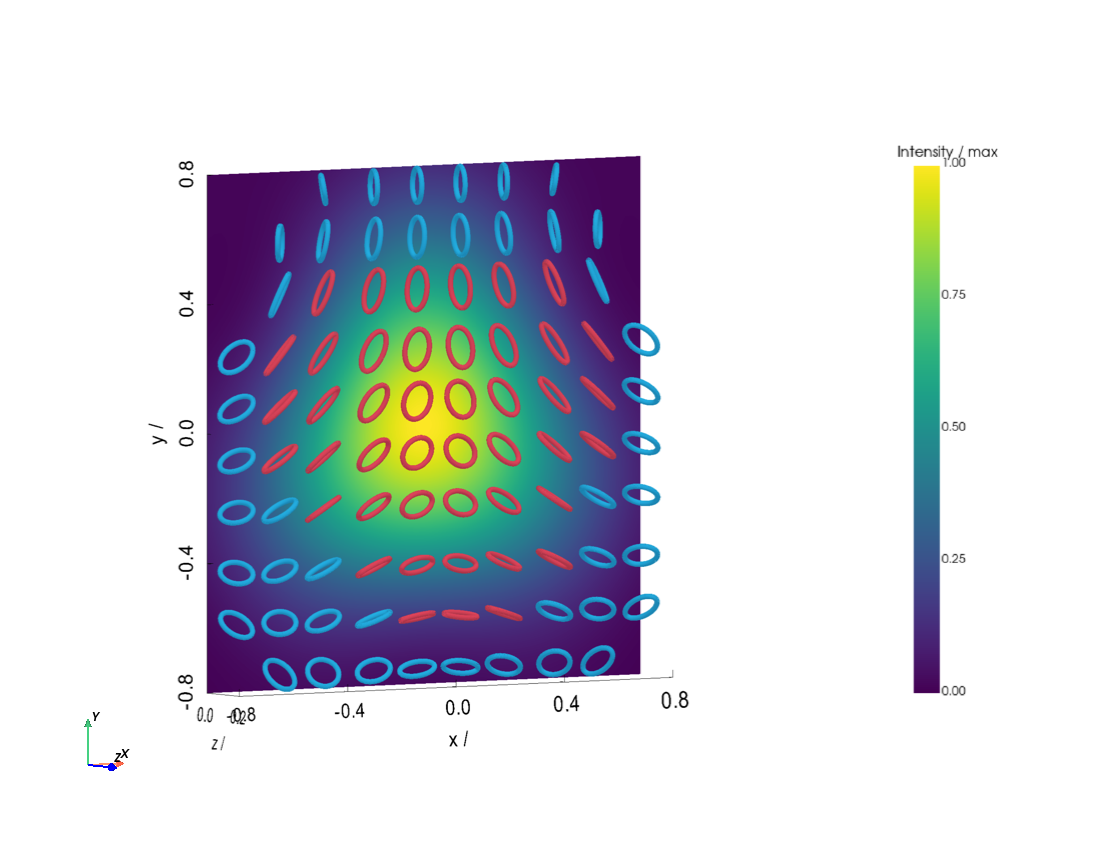
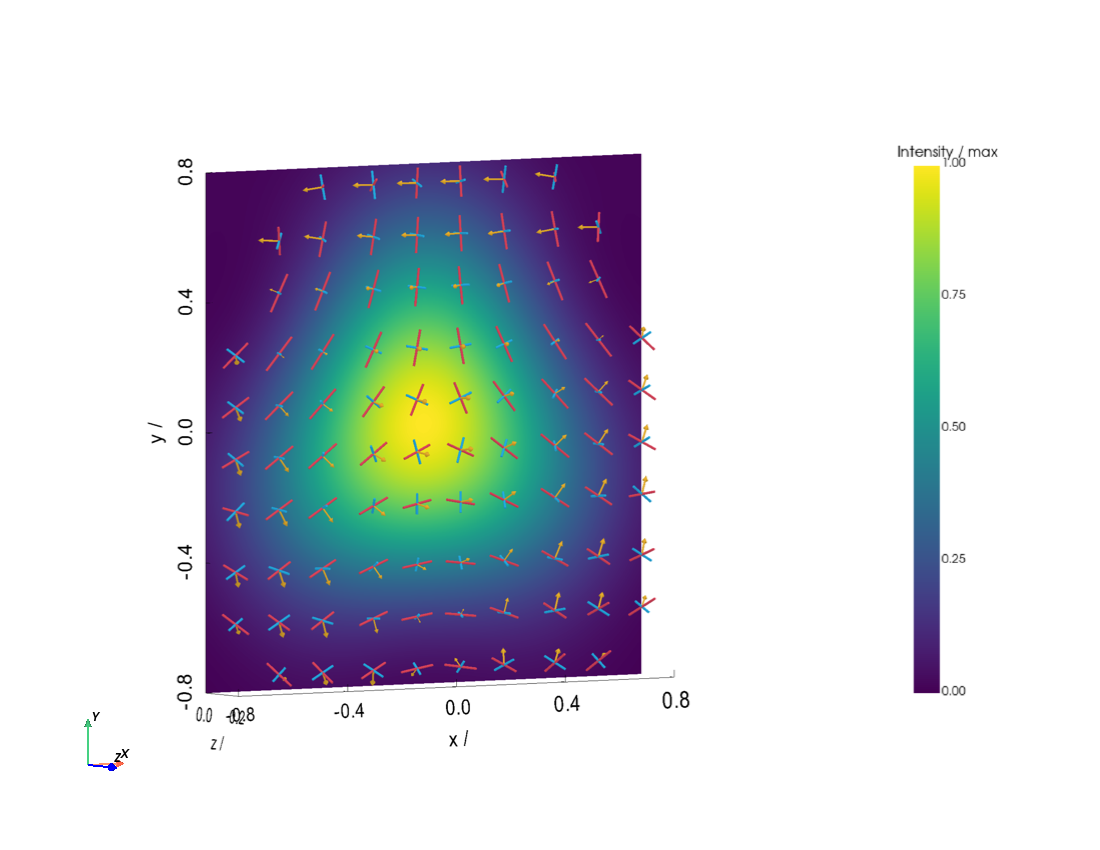

Side-by-side 3D views and interactive HTML controls

In [8]:
# Reuse notebook 02's renderer, pinned to the source versions used for this study.
# Immutable public GitHub blob endpoints avoid dependence on a moving main branch.
def load_atlas_renderer():
    import base64,hashlib,importlib,json,sys,urllib.request
    package=Path.cwd()/'_lemon_renderer'
    target=package/'visualization'
    target.mkdir(parents=True,exist_ok=True)
    blobs={
        'mathtubes.py':'d175dc020c0ece9d036726ff5c746246d0a8a203',
        'interactive_dashboard.py':'e15cdf32d120a60de1f13b21caab8b37892dc91b',
        'dashboard_controls.js':'97a0499b956f264fa11d925eaa63a0c0a5a178d7',
    }
    def blob_sha(data):
        return hashlib.sha1(b'blob '+str(len(data)).encode()+b'\0'+data).hexdigest()
    for name,expected in blobs.items():
        path=target/name
        if path.exists() and blob_sha(path.read_bytes())==expected:continue
        request=urllib.request.Request(
            f'https://api.github.com/repos/mffg1993/TightFocusingSolutions/git/blobs/{expected}',
            headers={'Accept':'application/vnd.github+json','User-Agent':'TightFocusingSolutions-Lemon-Notebook'})
        with urllib.request.urlopen(request,timeout=60) as response:
            payload=json.load(response)
        if payload.get('encoding')!='base64':raise RuntimeError('Unexpected renderer download format')
        data=base64.b64decode(payload['content'])
        if blob_sha(data)!=expected:raise RuntimeError(f'Renderer integrity check failed: {name}')
        path.write_bytes(data)
    for path in [package/'__init__.py',target/'__init__.py']:
        if not path.exists():path.write_text('')
    if str(package.parent) not in sys.path:sys.path.insert(0,str(package.parent))
    importlib.invalidate_caches()
    from _lemon_renderer.visualization import mathtubes,interactive_dashboard
    return mathtubes,interactive_dashboard

def html_explorer_controls(path, label='Open interactive HTML'):
    from IPython.display import HTML,JSON,FileLink,display
    try:
        from google.colab import output
    except ImportError:
        from html import escape
        href=escape(str(path),quote=True)
        display(HTML(f'<div style="margin:12px 0 20px"><a href="{href}" target="_blank" style="display:inline-block;padding:9px 15px;border:1px solid #bbb;border-radius:6px;text-decoration:none">{escape(label)} ↗</a> <a href="{href}" download>Download HTML</a></div>'))
        return
    import uuid
    from html import escape
    token='lemon-'+uuid.uuid4().hex
    def read_html():return JSON({'html':path.read_text(encoding='utf-8')})
    output.register_callback(token,read_html)
    display(HTML(r"""
    <div id="TOKEN" style="margin:12px 0 20px"><button data-action="open" style="padding:9px 15px;cursor:pointer">BUTTON_LABEL ↗</button>
    <button data-action="download">Download HTML</button><span role="status"></span></div>
    <script>(()=>{
      const root=document.getElementById('TOKEN');
      root.querySelectorAll('button').forEach(button=>button.onclick=async()=>{
        const tab=button.dataset.action==='open'?window.open('about:blank','_blank'):null;
        const status=root.querySelector('span');button.disabled=true;status.textContent=' Preparing explorer…';
        try{
          const result=await google.colab.kernel.invokeFunction('TOKEN',[],{});
          const payload=result.data['application/json'];
          if(!payload||!payload.html)throw Error('No HTML returned');
          const url=URL.createObjectURL(new Blob([payload.html],{type:'text/html;charset=utf-8'}));
          const link=document.createElement('a');link.href=url;
          if(button.dataset.action==='download'){link.download='FILE_NAME';link.click();}
          else{link.target='_blank';link.textContent='Open explorer';if(tab)tab.location.href=url;}
          status.replaceChildren(link);
        }catch(error){if(tab)tab.close();status.textContent=' '+error.message;}
        finally{button.disabled=false;}
      });
    })();</script>""".replace('TOKEN',token).replace('BUTTON_LABEL',escape(label)).replace('FILE_NAME',path.name)))


def show_image_pair(paths,titles):
    """A single output keeps the two 3D snapshots side by side in Colab/Jupyter."""
    import base64
    from html import escape
    from IPython.display import HTML,display
    panels=[]
    for path,title in zip(paths,titles):
        encoded=base64.b64encode(Path(path).read_bytes()).decode('ascii')
        panels.append(f'<figure style="flex:1 1 0;min-width:0;margin:0"><figcaption style="text-align:center;font-weight:600">{escape(title)}</figcaption><img alt="{escape(title)}" src="data:image/png;base64,{encoded}" style="display:block;width:100%;height:auto"></figure>')
    display(HTML('<div style="display:flex;gap:16px;align-items:flex-start">'+''.join(panels)+'</div>'))

mathtubes,interactive_dashboard=load_atlas_renderer()
import pyvista as pv
pv.OFF_SCREEN=True
STATIC_OPTIONS=dict(ngrid=GLYPH_POINTS,roi=FIELD_HALF_WIDTH,
    xlim=(-VIEW_HALF_WIDTH,VIEW_HALF_WIDTH),ylim=(-VIEW_HALF_WIDTH,VIEW_HALF_WIDTH),
    auto_roi=False,tube_radius_fraction=TUBE_RADIUS_FRACTION,
    minimum_relative_amplitude=np.sqrt(MINIMUM_RELATIVE_INTENSITY),
    linear_threshold=LINEAR_ELLIPTICITY_THRESHOLD,off_screen=True,size=(1100,850))
from IPython.display import Image
ELLIPSES_PNG=OUTPUT_DIR/'03_Lemon_Polarization_Ellipses.png'
AXES_PNG=OUTPUT_DIR/'03_Lemon_Polarization_Axes.png'
for mode,path,label in [('ellipse',ELLIPSES_PNG,'Full three-component polarization ellipses'),
                        ('all',AXES_PNG,'Major/minor axes and directed spin normals')]:
    plotter=mathtubes.plot_field_ellipses(E_lemon,x_field,x_field,
        glyph_mode=mode,screenshot=str(path),show=False,**STATIC_OPTIONS)
    plotter.close()

show_image_pair([ELLIPSES_PNG,AXES_PNG],
    ['Polarization ellipses','Major/minor axes and directed normals'])

# Prepare the HTML now, with its opening button immediately below the plot pair.
POLARIZATION_HTML=OUTPUT_DIR/'03_Lemon_Polarization_Explorer.html'
interactive_dashboard.export_polarization_dashboard(
    E_lemon,x_field,x_field,html_path=str(POLARIZATION_HTML),
    title='Tightly focused lemon — focal-plane polarization structure',
    ngrid=GLYPH_POINTS,roi=FIELD_HALF_WIDTH,
    xlim=(-VIEW_HALF_WIDTH,VIEW_HALF_WIDTH),ylim=(-VIEW_HALF_WIDTH,VIEW_HALF_WIDTH),auto_roi=False,
    tube_radius_fraction=TUBE_RADIUS_FRACTION,
    minimum_relative_amplitude=np.sqrt(MINIMUM_RELATIVE_INTENSITY),
    intensity_threshold=MINIMUM_RELATIVE_INTENSITY,
    linear_threshold=LINEAR_ELLIPTICITY_THRESHOLD)


html_explorer_controls(POLARIZATION_HTML,'Open polarization structure')


## 5. Using the interactive polarization explorer

Section 4 builds `03_Lemon_Polarization_Explorer.html` and places its opening/download buttons immediately below the paired 3D plots. The file contains the numerical field and Plotly and works offline after download.

The explorer has synchronized ellipse and axis views. Its controls change the shared x/y viewport, glyph density, tube thickness, glyph size, intensity opacity, intensity cutoff and linearity threshold. Checkboxes toggle the intensity plane and major/minor/normal displays. These operations resample the exported focal-plane field; optical parameters must be changed in the notebook.


In [10]:
# The HTML is already built in Section 4, directly below its paired plots.
print('Offline polarization explorer:',POLARIZATION_HTML)
print('Use the opening/download buttons below the Section 4 plots.')


Offline polarization explorer: lemon_outputs/03_Lemon_Polarization_Explorer.html
Use the opening/download buttons below the Section 4 plots.


## 6. Locate the C-point and analyze a contour
The background C-point search is a candidate search, followed by direct field refinement. It can miss closely spaced or tangential roots. By default the lemon study centers its circle on the refined candidate nearest the optical axis. Override `CENTER` explicitly to study another contour. A map always shows the actual circle, so its relation to the singularities is visible.

The circle must avoid dark points, circular states, and undersampling. Local axes are calculated from the full three-component complex field. The directed spin normal is calculated independently of the square-root branch used for the axes.

In [12]:
def find_cpoints(terms, half=0.55, grid=81, z=0., nt=401):
    from scipy.optimize import least_squares
    x=np.linspace(-half,half,grid); X,Y=np.meshgrid(x,x)
    E=field(X,Y,terms,z,nt,nrad=1001); I,Q=iq(E)
    candidates=[]
    for j in range(grid-1):
        for i in range(grid-1):
            v=Q[j:j+2,i:i+2]
            if v.real.min()<=0<=v.real.max() and v.imag.min()<=0<=v.imag.max():
                candidates.append([(x[i]+x[i+1])/2,(x[j]+x[j+1])/2])
    roots=[]
    def fun(p):
        _,q=iq(field(p[0],p[1],terms,z,nt)); return [q.real,q.imag]
    for p in candidates:
        if any(np.linalg.norm(np.asarray(p)-r)<0.25*(x[1]-x[0]) for r in roots): continue
        # Restrict refinement to the candidate cell and its immediate neighborhood.
        # This avoids unphysical root excursions and very large Bessel arguments.
        delta=2*(x[1]-x[0]); p=np.asarray(p)
        lo=np.maximum(p-delta,-half); hi=np.minimum(p+delta,half)
        scale=max(float(I.max()),1e-30)
        sol=least_squares(lambda v: np.asarray(fun(v))/scale,p,bounds=(lo,hi),
                          ftol=1e-12,xtol=1e-12,gtol=1e-12,max_nfev=30)
        v=sol.x
        ii,qq=iq(field(*v,terms,z,nt))
        if np.max(abs(v))<=half and ii>1e-8*I.max() and abs(qq)/ii<1e-8 and all(np.linalg.norm(v-r)>1e-5 for r in roots): roots.append(v)
    return x,I,Q,np.array(roots).reshape(-1,2)

In [13]:
def contour(terms, radius=.4, center=(0.,0.), z=0., samples=721, nt=801):
    if radius<=0 or samples<9: raise ValueError('Invalid contour')
    t=np.linspace(0,2*np.pi,samples)
    p=np.array([center[0]+radius*np.cos(t),center[1]+radius*np.sin(t),np.full_like(t,z)]).T
    p[-1]=p[0]
    E=field(p[:,0],p[:,1],terms,z,nt); I,Q=iq(E)
    if I.max()==0 or I.min()/I.max()<1e-10: raise ValueError('Contour meets a dark point')
    if np.min(abs(Q)/I)<1e-6: raise ValueError('Contour too close to circular polarization')
    phase=np.unwrap(np.angle(Q)); steps=np.diff(phase)
    if np.max(abs(steps))>np.pi/2: raise ValueError('Refine contour: phase step too large')
    w=int(np.rint((phase[-1]-phase[0])/(2*np.pi)))
    u=E/np.sqrt(I); rect=u*np.exp(-.5j*phase)
    a,b=rect.real.T,rect.imag.T
    assert np.allclose(a[-1],(-1)**w*a[0],atol=1e-8)
    g=np.imag(np.cross(E.conj().T,E.T))/I[:,None]
    d=a/np.linalg.norm(a,axis=1)[:,None]
    return dict(t=t,g=g,d=d,p=p,E=E,I=I,Q=Q,phase=phase,a=a,b=b,w=w,minq=float(np.min(abs(Q)/I)),minI=float(I.min()/I.max()))

### Ribbon visualization and quantitative meaning

The study shows **two different surfaces at identical spatial scales**:

- **Physical:** $\mathbf r+u a\hat{\boldsymbol\alpha}$, using the actual major-axis direction. It can fold or self-intersect where the director approaches the contour tangent.
- **Perpendicular component:** remove the component along the circle tangent $\hat{\mathbf t}$, then normalize: $\mathbf d_\perp\propto\hat{\boldsymbol\alpha}-(\hat{\boldsymbol\alpha}\cdot\hat{\mathbf t})\hat{\mathbf t}$. This displays the twist clearly. It is a labelled projection, not the full physical major-axis direction. Its magnitude must remain nonzero everywhere, which the code checks.

Neither construction prescribes a twist or stretches the vertical coordinate. The mesh seam follows the measured director parity. The amber boundary can be followed for **two circuits**: at one circuit the tracked endpoint lies on the opposite edge for odd parity; at two it returns.

### Three quantities that must be kept separate

| Quantity | Calculation | Meaning |
| --- | --- | --- |
| $Q$ winding $w$ | Unwrapped $\arg Q$ change divided by $2\pi$ | Odd $w$ gives major/minor director sign reversal |
| Projected half-turns $h$ | Unwrapped radial–axial director angle change divided by $\pi$ | Signed rotation in the specified moving frame; not automatically $w$ |
| Spin-normal closure | $\hat{\boldsymbol\gamma}(0)\cdot\hat{\boldsymbol\gamma}(2\pi)$ | $+1$ where defined; the normal is a directed vector |

For the circle's outward radial unit vector $\hat{\mathbf r}$ and fixed $+z$ direction, we define
$$\vartheta(t)=\mathrm{unwrap}\,\mathrm{atan2}(\hat{\boldsymbol\alpha}\cdot\hat{\mathbf z},\hat{\boldsymbol\alpha}\cdot\hat{\mathbf r}),\qquad h=[\vartheta(2\pi)-\vartheta(0)]/\pi.$$
This is a count for this **radial–axial projection and contour orientation**; it does not independently certify an embedded physical strip. Its parity should agree with $w$ when the projection stays nonzero. Refinement checks include this rotation, as well as the complex field and $Q$ winding.

In [15]:
def mobius_view(c, view='perpendicular'):
    """Remove tangential components for an explicitly labelled framing view."""
    result=dict(c)
    if view=='physical':
        result['view_label']='Physical major-axis ribbon'
        return result
    if view!='perpendicular': raise ValueError('Choose physical or perpendicular')
    t=c['t']; tangent=np.column_stack([-np.sin(t),np.cos(t),0*t])
    d=c['d']-np.sum(c['d']*tangent,axis=1)[:,None]*tangent
    lengths=np.linalg.norm(d,axis=1)
    if lengths.min()<1e-5: raise ValueError('Perpendicular projection vanishes; use physical view')
    result['d']=d/lengths[:,None]
    result['view_label']='Perpendicular-component ribbon'
    print('Minimum perpendicular director magnitude: %.5g' % lengths.min())
    return result

def mobius_mesh(c, width=.075, across=9):
    if width<=0 or across<2: raise ValueError('Invalid ribbon width/resolution')
    m=len(c['p'])-1; u=np.linspace(-1,1,across)
    v=(c['p'][:-1,None,:]+width*u[None,:,None]*c['d'][:-1,None,:]).reshape(-1,3)
    faces=[]
    for i in range(m):
        j=(i+1)%m
        ks=np.arange(across)
        if j==0 and c['w']%2: ks=ks[::-1]
        for k0 in range(across-1):
            a=i*across+k0; b=a+1; cc=j*across+ks[k0]; dd=j*across+ks[k0+1]
            faces.extend([(a,b,cc),(b,dd,cc)])
    return v,np.asarray(faces)

def closure_report(c):
    print('Q winding:',c['w'], '|', 'Möbius parity (odd)' if c['w']%2 else 'Orientable parity (even)')
    print('Minimum |Q|/I: %.5g; minimum relative intensity: %.5g' %
          (np.min(abs(c['Q'])/c['I']),c['I'].min()/c['I'].max()))
    print('\nAxis                endpoint dot product     closure error')
    for name,key in [('Major alpha','a'),('Minor beta','b'),('Spin normal gamma','g')]:
        v=c[key]; norm=np.linalg.norm(v,axis=1)
        if norm.min()<1e-7:
            print(f'{name:20s} undefined somewhere on contour'); continue
        v=v/norm[:,None]; sign=1 if key=='g' else (-1.)**c['w']
        print(f'{name:20s} {np.dot(v[0],v[-1]):+.9f}             {np.linalg.norm(v[-1]-sign*v[0]):.2e}')
    print('Boundary components:',1 if c['w']%2 else 2)

def mobius_explorer(c,width=.075,title='Lemon'):
    v,fcs=mobius_mesh(c,width); p=c['p']; d=c['d']; odd=c['w']%2
    fig=go.Figure()
    fig.add_trace(go.Mesh3d(x=v[:,0],y=v[:,1],z=v[:,2],i=fcs[:,0],j=fcs[:,1],k=fcs[:,2],
        color='#53ac87',opacity=.9,name=c.get('view_label','Physical major-axis ribbon'),showlegend=True,
        lighting=dict(ambient=.8,diffuse=.6,specular=.05),hoverinfo='skip'))
    def line(pts,name,color,w=4,**kw):
        return go.Scatter3d(x=pts[:,0],y=pts[:,1],z=pts[:,2],mode='lines',name=name,line=dict(color=color,width=w),**kw)
    if odd:
        edge=np.vstack([p+width*d,p[1:]-width*d[1:]])
        fig.add_trace(line(edge,'One continuous boundary (two circuits)','#df8a15',6))
    else:
        for s in [-1,1]:fig.add_trace(line(p+s*width*d,'Boundary edge','#df8a15',5))
    fig.add_trace(line(p,'Sampling contour','#666666',3))
    ribs=[]
    for j in np.linspace(0,len(p)-2,24,dtype=int):ribs.extend([p[j]-width*d[j],p[j]+width*d[j],[np.nan]*3])
    fig.add_trace(line(np.array(ribs),'Local director segments','#23684f',2))
    fig.add_trace(line(np.array([p[0],p[0]+width*d[0]]),'Start endpoint','#bd3d47',9))
    fig.add_trace(line(np.array([p[0],p[0]+width*d[-1]]),'After one circuit','#7b2638',9))
    moving=len(fig.data)
    def moving_traces(lap,j):
        direction=((-1.)**(c['w']*lap))*d[j]
        return [line(np.array([p[j]-width*direction,p[j]+width*direction]),'Tracked director','#134a35',10,showlegend=False),
                go.Scatter3d(x=[p[j,0]+width*direction[0]],y=[p[j,1]+width*direction[1]],z=[p[j,2]+width*direction[2]],
                    mode='markers',marker=dict(size=7,color='#ffb629',line=dict(color='#704b00',width=2)),name='Tracked endpoint',showlegend=False)]
    fig.add_traces(moving_traces(0,0)); frames=[]; steps=[]
    for q in range(97):
        turns=2*q/96; lap=min(int(turns),1); j=int(round((turns-lap)*(len(p)-1)))
        frames.append(go.Frame(name=str(q),data=moving_traces(lap,j),traces=[moving,moving+1]))
        steps.append(dict(label=f'{turns:.2f}',method='animate',args=[[str(q)],dict(mode='immediate',frame=dict(duration=0,redraw=True),transition=dict(duration=0))]))
    fig.frames=frames
    fig.update_layout(title=f'{title}: {c.get("view_label","Physical major-axis ribbon")} · Q winding={c["w"]:+d} · '+('opposite edges join' if odd else 'same edges join'),
        height=720,scene=dict(aspectmode='data',xaxis_title='x / λ₀',yaxis_title='y / λ₀',zaxis_title='z / λ₀',camera=dict(eye=dict(x=1.4,y=-1.8,z=1.1))),
        margin=dict(l=0,r=0,b=80,t=65),legend=dict(orientation='h',y=1.02),
        updatemenus=[dict(type='buttons',x=0,y=-.06,buttons=[dict(label='Follow edge',method='animate',args=[None,dict(fromcurrent=True,frame=dict(duration=60,redraw=True),transition=dict(duration=0))]),dict(label='Pause',method='animate',args=[[None],dict(mode='immediate',frame=dict(duration=0,redraw=False))])])],
        sliders=[dict(active=0,currentvalue=dict(prefix='Circuits: '),steps=steps,x=.26,len=.72,y=-.06)])
    return fig

In [16]:
def axis_for_view(c, axis='major', view='physical'):
    if axis not in ('major','minor'): raise ValueError('Choose major or minor')
    result=dict(c); key='a' if axis=='major' else 'b'
    norm=np.linalg.norm(c[key],axis=1)
    if norm.min()<1e-7: raise ValueError('Selected axis is undefined on this contour')
    result['d']=c[key]/norm[:,None]
    result=mobius_view(result,view)
    result['view_label']=(f'Physical {axis}-axis ribbon' if view=='physical'
                          else f'Perpendicular {axis}-axis component')
    return result

def projected_rotation(c):
    t=c['t']; radial=np.column_stack([np.cos(t),np.sin(t),0*t])
    dr=np.sum(c['d']*radial,axis=1); dz=c['d'][:,2]
    minimum=float(np.hypot(dr,dz).min())
    if minimum<1e-5: raise ValueError('Projected director vanishes; half-turn count undefined')
    angle=np.unwrap(np.arctan2(dz,dr))
    if np.max(abs(np.diff(angle)))>np.pi/2: raise ValueError('Refine contour for projected rotation')
    h=(angle[-1]-angle[0])/np.pi
    if abs(h-round(h))>1e-6: raise ValueError('Projected rotation does not close')
    if (round(h)-c['w'])%2: raise ValueError('Projection and Q parity disagree')
    return angle,int(round(h)),minimum

def draw_ribbon(ax,c,width):
    from mpl_toolkits.mplot3d.art3d import Poly3DCollection
    vertices,faces=mobius_mesh(c,width)
    ax.add_collection3d(Poly3DCollection(vertices[faces],facecolor='#53ac87',edgecolor='none',alpha=.88))
    p,d=c['p'],c['d']
    if c['w']%2:
        edge=np.vstack([p+width*d,p[1:]-width*d[1:]])
        ax.plot(*edge.T,color='#df8a15',lw=2)
    else:
        for sign in [-1,1]:ax.plot(*(p+sign*width*d).T,color='#df8a15',lw=2)
    ax.plot(*p.T,color='#666666',ls='--',lw=1)
    for j in np.linspace(0,len(p)-2,20,dtype=int):
        ax.plot(*np.array([p[j]-width*d[j],p[j]+width*d[j]]).T,color='#23684f',lw=1)
    mid=(vertices.min(0)+vertices.max(0))/2; span=np.ptp(vertices,axis=0).max()
    for setter,center in zip([ax.set_xlim,ax.set_ylim,ax.set_zlim],mid):setter(center-.55*span,center+.55*span)
    ax.set_box_aspect((1,1,1));ax.view_init(elev=30,azim=-65)
    ax.set(xlabel='x / λ₀',ylabel='y / λ₀',zlabel='z / λ₀',title=c['view_label'])

def study_overview(name,c,background,roots,width):
    physical=axis_for_view(c,'major','physical'); projected=axis_for_view(c,'major','perpendicular')
    angle,h,minimum=projected_rotation(c)
    fig=plt.figure(figsize=(13,10),layout='constrained')
    ax=fig.add_subplot(223)
    x,I,Q=background
    image=ax.imshow(abs(Q)/np.maximum(I,1e-30),origin='lower',extent=[x[0],x[-1],x[0],x[-1]],vmin=0,vmax=1,cmap='viridis')
    ax.plot(c['p'][:,0],c['p'][:,1],color='orange',label='Actual contour')
    if len(roots):ax.scatter(*roots.T,marker='x',c='red',s=55,label='Refined C-point candidates')
    ax.scatter(c['p'][0,0],c['p'][0,1],c='white',s=30,label='Start, t=0')
    ax.set(xlabel='x / λ₀',ylabel='y / λ₀',title='Full 3D circularity |Q|/I');ax.legend(fontsize=8,loc="upper right");fig.colorbar(image,ax=ax)
    draw_ribbon(fig.add_subplot(221,projection='3d'),physical,width)
    draw_ribbon(fig.add_subplot(222,projection='3d'),projected,width)
    ax=fig.add_subplot(224); turns=c['t']/(2*np.pi)
    ax.plot(turns,(c['phase']-c['phase'][0])/(2*np.pi),label=f'Q phase / 2π: w={c["w"]:+d}')
    ax.plot(turns,(angle-angle[0])/np.pi,label=f'Projected angle / π: h={h:+d}')
    ax.set(xlabel='Circuits',ylabel='Accumulated rotation',title='Winding and projected half-turns');ax.grid(alpha=.2);ax.legend()
    fig.suptitle(f'{name} input — calculated focused topology',fontsize=16)
    plt.show();plt.close(fig)
    return fig,h,minimum

def ribbon_viewer_pair(c,width=.075,title='Lemon',axis='major'):
    """Both ribbon views share one two-circuit animation slider."""
    from copy import deepcopy
    from plotly.subplots import make_subplots
    views=[mobius_explorer(axis_for_view(c,axis,mode),width,title=title)
           for mode in ['physical','perpendicular']]
    combined=make_subplots(rows=1,cols=2,specs=[[{'type':'scene'},{'type':'scene'}]],
        subplot_titles=[f'Physical {axis}-axis ribbon',f'Perpendicular {axis}-axis component'],
        horizontal_spacing=.06)
    offsets=[]
    for column,view in enumerate(views,1):
        offsets.append(len(combined.data))
        for trace in view.data:
            trace=deepcopy(trace);trace.showlegend=False
            combined.add_trace(trace,row=1,col=column)
    frames=[]
    for first,second in zip(views[0].frames,views[1].frames):
        data=[];indices=[]
        for column,frame in enumerate([first,second]):
            for trace,index in zip(frame.data,frame.traces):
                trace=deepcopy(trace);trace.update(scene='scene' if column==0 else 'scene2')
                data.append(trace);indices.append(offsets[column]+index)
        frames.append(go.Frame(name=first.name,data=data,traces=indices))
    combined.frames=frames
    combined.update_layout(title=f'{title} — physical and projected ribbons',height=700,
        scene=views[0].layout.scene.to_plotly_json(),scene2=views[1].layout.scene.to_plotly_json(),
        updatemenus=deepcopy(views[0].layout.updatemenus),sliders=deepcopy(views[0].layout.sliders),
        margin=dict(l=0,r=0,t=80,b=110),showlegend=False)
    return combined

def run_study(name,radius=.4,center=None,width=.075,axis='major',view='perpendicular',samples=721,nt=801):
    terms=CASES[name]
    half=max(.55,radius+.1) if center is None else max(.55,np.max(abs(np.asarray(center)))+radius+.1)
    x,I,Q,roots=find_cpoints(terms,half=half,grid=81,nt=401)
    if center is None:
        if not len(roots): raise ValueError('No C-point found; supply CENTER explicitly')
        center=tuple(roots[np.argmin(np.linalg.norm(roots,axis=1))])
    c=contour(terms,radius,center,samples=samples,nt=nt)
    print(f'{name} input: center={tuple(float(v) for v in center)}, radius={radius:.4g} λ₀')
    print('Refined C-point candidates:\n',roots)
    closure_report(c)
    overview,h,minimum=study_overview(name,c,(x,I,Q),roots,width)
    print(f'Radial–axial major-axis half-turns: {h:+d}; minimum projected magnitude: {minimum:.6g}')
    print('Changing contour center, radius or optical parameters can change these results.')
    viewer=ribbon_viewer_pair(c,width,title=name+' input',axis=axis)
    html_path=OUTPUT_DIR/f'03_{name}_Mobius_Explorer.html'
    viewer.write_html(str(html_path),include_plotlyjs=True,auto_play=False)
    html_explorer_controls(html_path,'Open Möbius ribbon structure')
    result=dict(name=name,c=c,terms=terms,center=center,radius=radius,width=width,axis=axis,view=view,
                html_path=html_path,roots=roots,halfturns=h,projection_min=minimum,overview=overview,viewer=viewer,samples=samples,nt=nt)
    RESULTS[name]=result
    return result

## 7. Lemon input — explicit Möbius study

$$\mathbf E_{in}=(-U_{-1}\mathbf e_R+U_0\mathbf e_L)/\sqrt2.$$

Compare Q winding with rotation in the specified radial–axial frame; these are distinct quantities.

Run the following cell independently after the setup, solver and contour definitions. `CENTER=None` selects the refined C-point nearest the optical axis; set `(x,y)` to choose a different center. The overview places the full physical and projected major-axis ribbons side by side, with the C-point map and winding diagnostic below. The **Open Möbius ribbon structure** button underneath opens both 3D ribbons side by side. They share a two-circuit animation slider; `AXIS` selects the major or minor director for both views. At **Circuits = 1.00**, compare the amber endpoint with its starting location; at **2.00**, check that it returns.

Lemon input: center=(-4.638991527122592e-12, -4.817199606493977e-12), radius=0.4 λ₀
Refined C-point candidates:
 [[-4.63899153e-12 -4.81719961e-12]]
Q winding: -1 | Möbius parity (odd)
Minimum |Q|/I: 0.57346; minimum relative intensity: 0.78527

Axis                endpoint dot product     closure error
Major alpha          -1.000000000             1.24e-16
Minor beta           -1.000000000             5.09e-16
Spin normal gamma    +1.000000000             0.00e+00
Boundary components: 1
Minimum perpendicular director magnitude: 0.21512
Radial–axial major-axis half-turns: +3; minimum projected magnitude: 0.215122
Changing contour center, radius or optical parameters can change these results.
Minimum perpendicular director magnitude: 0.21512


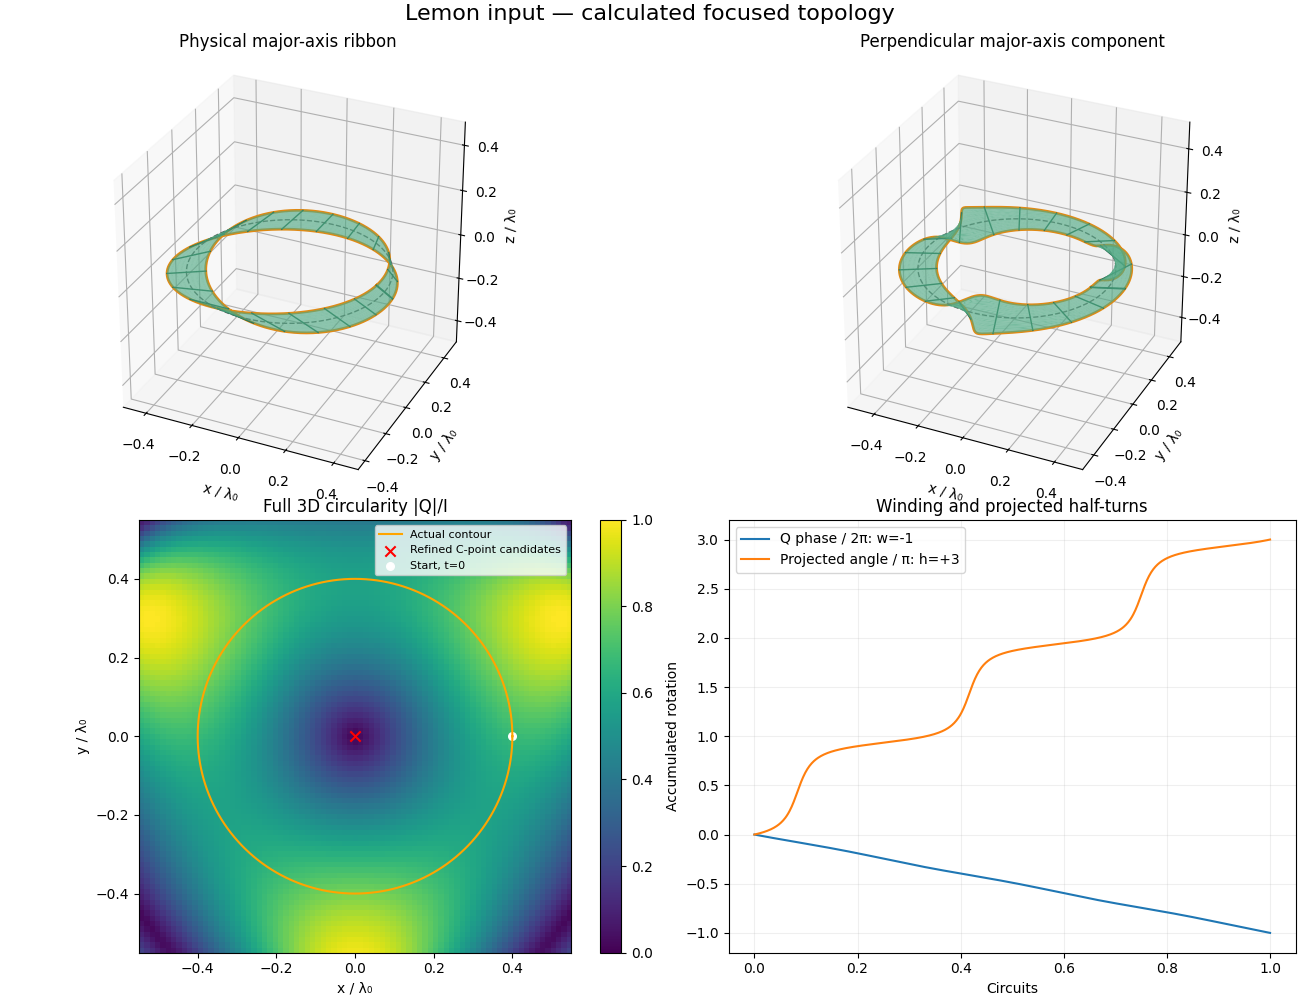

Side-by-side 3D views and interactive HTML controls

In [18]:
# Lemon: independent controls. Change these values and rerun this cell.
LEMON_RADIUS = .4
LEMON_CENTER = None
LEMON_WIDTH = .075
LEMON_AXIS = 'major'       # 'major' or 'minor'
lemon_study = run_study('Lemon',radius=LEMON_RADIUS,center=LEMON_CENTER,
    width=LEMON_WIDTH,axis=LEMON_AXIS)

## 8. Verify the field and topology

First compare the interpolated Cartesian field used in the polarization explorer with **direct quadrature at selected Cartesian pixels**, including the origin. This checks the numerical interpolation used for the map. Next refine polar quadrature and contour sampling and check Q winding, projected rotation, and actual mesh boundary components. These are numerical consistency checks; they do not independently validate the focusing theory against experiment.

In [11]:
# Compare direct field values with the exported Cartesian array at 25 pixels.
probe=np.unique(np.rint(np.linspace(0,FIELD_POINTS-1,5)).astype(int))
JJ,II=np.meshgrid(probe,probe,indexing='ij')
direct=field(x_field[II],x_field[JJ],LEMON_TERMS,z=0.,nt=FIELD_THETA_NODES)
map_error=np.linalg.norm(E_lemon[:,JJ,II]-direct)/np.linalg.norm(direct)
print(f'Cartesian radial-interpolation error at probe pixels: {map_error:.3e}')
assert map_error<1e-4,'Increase FIELD_RADIAL_NODES and rerun the field/visualizations'
assert np.array_equal(I_lemon,np.sum(np.abs(E_lemon)**2,axis=0))
assert set(RESULTS)=={'Lemon'},'This notebook calculates the lemon case only'

Cartesian radial-interpolation error at probe pixels: 4.323e-06


In [12]:
def mesh_boundary_components(c,width):
    from collections import Counter
    vertices,faces=mobius_mesh(c,width)
    edges=Counter(tuple(sorted((int(a),int(b)))) for face in faces for a,b in zip(face,np.roll(face,-1)))
    if max(edges.values())>2:raise AssertionError('Nonmanifold mesh edge')
    adjacency={}
    for (a,b),count in edges.items():
        if count==1:adjacency.setdefault(a,[]).append(b);adjacency.setdefault(b,[]).append(a)
    assert adjacency and all(len(v)==2 for v in adjacency.values())
    seen=set();components=0
    for node in adjacency:
        if node in seen:continue
        components+=1;todo=[node]
        while todo:
            node=todo.pop()
            if node in seen:continue
            seen.add(node);todo.extend(adjacency[node])
    return components

for name,r in RESULTS.items():
    c=r['c'];nt=r['nt'];samples=r['samples']
    angular=contour(r['terms'],r['radius'],r['center'],samples=samples,nt=2*nt-1)
    refined=contour(r['terms'],r['radius'],r['center'],samples=2*samples-1,nt=nt)
    relative=np.linalg.norm(c['E']-angular['E'])/np.linalg.norm(angular['E'])
    h1=projected_rotation(angular)[1];h2=projected_rotation(refined)[1]
    assert angular['w']==refined['w']==c['w']
    assert h1==h2==r['halfturns']
    boundary=mesh_boundary_components(c,r['width'])
    assert boundary==(1 if c['w']%2 else 2)
    assert relative<1e-6,'Polar quadrature has not converged'
    print(f'{name}: field change={relative:.3e}; Q winding={c["w"]:+d}; projected half-turns={h1:+d}; boundary components={boundary}')

Lemon: field change=1.768e-12; Q winding=-1; projected half-turns=+3; boundary components=1


### Optional: vary the radius around each selected C-point
A singularity crossing, loss of intensity, or vanishing projection can change the result or invalidate a contour. Missing points are rejected calculations. This sweep uses each study's chosen center and the major axis.

In [13]:
RUN_RADIUS_SWEEP = False
if RUN_RADIUS_SWEEP:
    radii=np.linspace(.04,.8,39)
    fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    for name,r in RESULTS.items():
        winding=[];halfturns=[]
        for radius in radii:
            try:c=contour(r['terms'],radius,r['center'],samples=721,nt=401);winding.append(c['w'])
            except ValueError:winding.append(np.nan);halfturns.append(np.nan);continue
            try:halfturns.append(projected_rotation(c)[1])
            except ValueError:halfturns.append(np.nan)
        axs[0].plot(radii,winding,'.-',label=name);axs[1].plot(radii,halfturns,'.-',label=name)
    for ax,label in zip(axs,['Q winding','Radial–axial half-turns']):
        ax.set(xlabel='Radius / λ₀',ylabel=label);ax.legend();ax.grid(alpha=.2)
    plt.show()

## 9. Download the lemon study
The HTML explorer, numerical field and PNG figures are generated by the field sections. Set `EXPORT_LEMON_BUNDLE=True` below to package those files together with the Möbius edge-following viewer and overview. Both HTML tools work offline after download.

In [14]:
EXPORT_LEMON_BUNDLE = False
if EXPORT_LEMON_BUNDLE:
    import zipfile
    r=RESULTS['Lemon']
    mobius_html=OUTPUT_DIR/'03_Lemon_Mobius_Explorer.html'
    r['viewer'].write_html(str(mobius_html),include_plotlyjs=True,auto_play=False)
    overview=OUTPUT_DIR/'03_Lemon_Mobius_Overview.png'
    r['overview'].savefig(overview,dpi=160)
    paths=[POLARIZATION_HTML,FIELD_NPZ,INTENSITY_PNG,ELLIPSES_PNG,AXES_PNG,mobius_html,overview]
    archive=OUTPUT_DIR/'03_Lemon_Focusing_Study.zip'
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as zf:
        for path in paths:zf.write(path,path.name)
    try:
        from google.colab import files
        files.download(str(archive))
    except ImportError:
        from IPython.display import FileLink
        display(FileLink(str(archive)))

## 10. Interpretation and limitations

The field maps, static three-dimensional glyphs and HTML explorer show the calculated focal-plane polarization structure. The ribbon follows the **same solver and incident lemon field** on a continuous contour. The HTML's local arrow signs do not replace the contour phase-unwrapping calculation.

For a complex field, $I=\mathbf E^*\cdot\mathbf E$ and $Q=\mathbf E\cdot\mathbf E$. At nonzero intensity, $Q=0$ indicates circular polarization in three dimensions. This differs from circularity of the transverse projection. With $\psi=\operatorname{unwrap}\arg Q$, the normalized semiaxes are $\boldsymbol\alpha=\operatorname{Re}(\mathbf E e^{-i\psi/2})/\sqrt I$ and $\boldsymbol\beta=\operatorname{Im}(\mathbf E e^{-i\psi/2})/\sqrt I$. The directed spin normal is $\boldsymbol\gamma=\operatorname{Im}(\mathbf E^*\times\mathbf E)/I$.

An odd winding of Q produces axis sign reversal. The geometric rotation count depends on the specified projection/frame and must be calculated separately. A physical ribbon can fold or self-intersect even with correct nonorientable mesh connectivity. The perpendicular-component view removes the director component along the sampling-circle tangent; it is labelled as a projection and checked for nonvanishing magnitude. The directed spin normal remains single-valued wherever defined.

The model excludes refractive-index interfaces, aberrations, broadband effects and nonlinear response. The maps use radial interpolation; the contour uses direct evaluation. Convergence checks test numerical consistency within this model. A focused lemon/star/monstar separatrix classification, C-line tracing, and full focal-volume visualization would require further analysis.

Related experimental context: [Bauer et al., Science 347, 964–966 (2015)](https://doi.org/10.1126/science.1260635). These atlas inputs are not assumed to reproduce that experiment exactly. The focusing convention follows [Tutorial 01](https://github.com/mffg1993/TightFocusingSolutions/blob/main/tutorials/01_Thesis_Bessel_Integral_Decomposition.ipynb) and the renderer follows [Tutorial 02](https://github.com/mffg1993/TightFocusingSolutions/blob/main/tutorials/02_Focal_Plane_Polarization_Atlas_PyVista.ipynb).